# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.3f}'.format)

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv('data/AviationData_cleaned.csv', parse_dates=['Event.Date'])
print(df.shape)
df.head()

(57032, 26)


,Event.Id,Investigation.Type,Event.Date,Location,Country,Airport.Code,Airport.Name,Injury.Severity,Aircraft.damage,Aircraft.Category,...,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Year,Total.Passengers,Fatal.Serious.Frac,Destroyed,Make.Model
0,20001214X42095,Accident,1983-01-01,"NEWPORT, OR",United States,ONP,NEWPORT MUNICIPAL,Non-Fatal,Substantial,Airplane,...,0.000,1.000,3.000,VMC,Approach,1983,4.000,0.000,0.000,Cessna 182P
1,20001214X42067,Accident,1983-01-01,"WOODBINE, IA",United States,3YR,MUNICIPAL,Non-Fatal,Substantial,Airplane,...,0.000,0.000,2.000,VMC,Landing,1983,2.000,0.000,0.000,Cessna 182RG
2,20001214X42063,Accident,1983-01-01,"MARYVILLE, MO",United States,78Y,RANKIN,Non-Fatal,Substantial,Airplane,...,0.000,0.000,1.000,VMC,Takeoff,1983,1.000,0.000,0.000,Cessna 182P
3,20001214X42018,Accident,1983-01-01,"UPLAND, CA",United States,CCB,CABLE,Non-Fatal,Substantial,Airplane,...,0.000,2.000,0.000,VMC,Approach,1983,2.000,0.000,0.000,Piper PA28R200
4,20001214X41951,Accident,1983-01-01,"SPRINGBROOK, WI",United States,NaN,SPRINGBROOK,Non-Fatal,Substantial,Airplane,...,0.000,0.000,2.000,VMC,Landing,1983,2.000,0.000,0.000,Cessna 140


In [3]:
# helper: summary table of the two safety metrics with sample sizes and 95% confidence intervals
def safety_summary(data, by, min_n=1):
    g = data.groupby(by)
    out = pd.DataFrame({
        'n_events': g.size(),
        'inj_mean': g['Fatal.Serious.Frac'].mean(),
        'inj_ci95': 1.96 * g['Fatal.Serious.Frac'].sem(),
        'n_damage_known': g['Destroyed'].count(),
        'destroyed_rate': g['Destroyed'].mean(),
        'destroyed_ci95': 1.96 * g['Destroyed'].sem(),
    })
    return out[out['n_events'] >= min_n]

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

`Total.Passengers` is recorded per *event*, so a Boeing 737 positioning flight with 3 crew on board would look like a "small" plane. To classify the **plane type** rather than the individual flight, we look at all accidents of each `Make.Model` and take the **90th percentile of occupants**: a type is *Large* if that value exceeds 20, otherwise *Small*.

- A high percentile captures the type's *capacity* (airliners regularly fly full, even if some accidents are ferry/cargo flights with only crew).
- Using the 90th percentile rather than the maximum protects against single mis-entered occupant counts (a handful of Cessna 172 records list >20 people).
- Limitation: pure freighter variants (e.g. 747-200F) never carry >20 people and so stay in the *Small* group; they are only a few dozen rows out of ~55,000.

In [4]:
occupants_p90 = df.groupby('Make.Model')['Total.Passengers'].quantile(0.9)
large_types = occupants_p90[occupants_p90 > 20].index
df['Size'] = np.where(df['Make.Model'].isin(large_types), 'Large', 'Small')

small = df[df['Size'] == 'Small']
large = df[df['Size'] == 'Large']
print(df['Size'].value_counts())
print('\nLarge-plane makes:\n', large['Make'].value_counts())

Size
Small    54927
Large     2105
Name: count, dtype: int64

Large-plane makes:
 Make
Boeing               1210
Mcdonnell Douglas     266
Airbus                200
Embraer               123
Bombardier            103
Douglas                68
De Havilland           53
Beech                  37
Lockheed               34
Piper                   4
Fairchild               3
Grumman                 2
Gulfstream              2
Name: count, dtype: int64


In [5]:
safety_summary(df, 'Size')

,n_events,inj_mean,inj_ci95,n_damage_known,destroyed_rate,destroyed_ci95
Size,,,,,,
Large,2105,0.077,0.011,1201,0.129,0.019
Small,54927,0.273,0.004,54338,0.206,0.003


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

To keep the comparisons statistically meaningful, a make is only ranked if it has enough events **within its size group**: at least **50** for small planes (data are plentiful, and this removes a few freighter/business-jet rows from airliner makes) and at least **20** for large planes (only ~2,100 large-plane events exist in total). Only 9 large-plane makes clear this bar, so the large group shows fewer than 15.

In [6]:
MIN_EVENTS_SMALL, MIN_EVENTS_LARGE = 50, 20
small_makes = safety_summary(small, 'Make', MIN_EVENTS_SMALL).sort_values('inj_mean')
large_makes = safety_summary(large, 'Make', MIN_EVENTS_LARGE).sort_values('inj_mean')
small_top = small_makes.head(15)
large_top = large_makes.head(15)
small_top

,n_events,inj_mean,inj_ci95,n_damage_known,destroyed_rate,destroyed_ci95
Make,,,,,,
Waco,99,0.130,0.064,98,0.102,0.060
Great Lakes,54,0.139,0.091,54,0.111,0.085
Cubcrafters,68,0.140,0.079,68,0.000,0.000
Swearingen,85,0.147,0.074,78,0.128,0.075
Maule,488,0.159,0.031,488,0.088,0.025
Schweizer,140,0.171,0.063,140,0.200,0.066
Boeing,360,0.172,0.036,342,0.126,0.035
Helio,68,0.183,0.089,67,0.164,0.089
Aviat,223,0.200,0.050,222,0.063,0.032


In [7]:
large_top

,n_events,inj_mean,inj_ci95,n_damage_known,destroyed_rate,destroyed_ci95
Make,,,,,,
Mcdonnell Douglas,266,0.036,0.019,175,0.086,0.042
Lockheed,34,0.043,0.059,23,0.130,0.141
Bombardier,103,0.047,0.035,71,0.056,0.054
Boeing,1210,0.069,0.013,628,0.116,0.025
Embraer,123,0.073,0.041,73,0.096,0.068
Airbus,200,0.089,0.037,95,0.179,0.077
De Havilland,53,0.156,0.090,39,0.256,0.139
Douglas,68,0.210,0.094,57,0.246,0.113
Beech,37,0.326,0.153,33,0.303,0.159


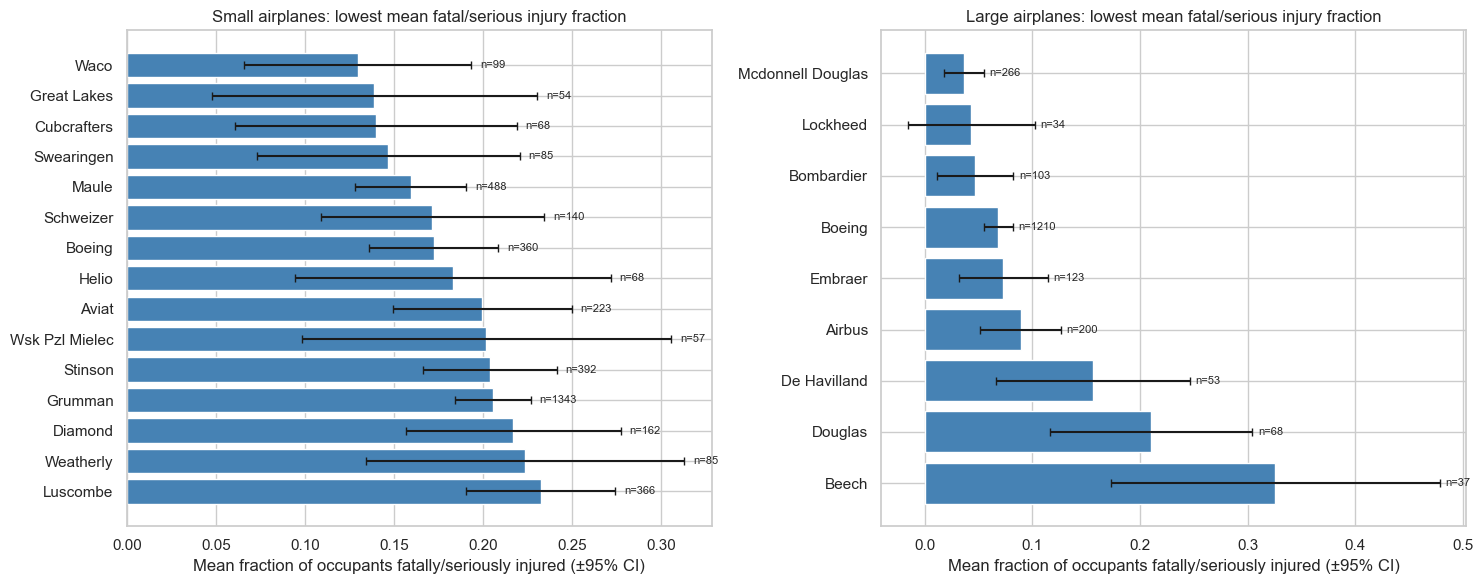

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, tbl, title in [(axes[0], small_top, 'Small airplanes'), (axes[1], large_top, 'Large airplanes')]:
    ax.barh(tbl.index, tbl['inj_mean'], xerr=tbl['inj_ci95'], color='steelblue', capsize=3)
    for y, (v, n) in enumerate(zip(tbl['inj_mean'], tbl['n_events'])):
        ax.text(v + tbl['inj_ci95'].iloc[y] + 0.005, y, f'n={n}', va='center', fontsize=8)
    ax.invert_yaxis()
    ax.set_title(f'{title}: lowest mean fatal/serious injury fraction')
    ax.set_xlabel('Mean fraction of occupants fatally/seriously injured (±95% CI)')
plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

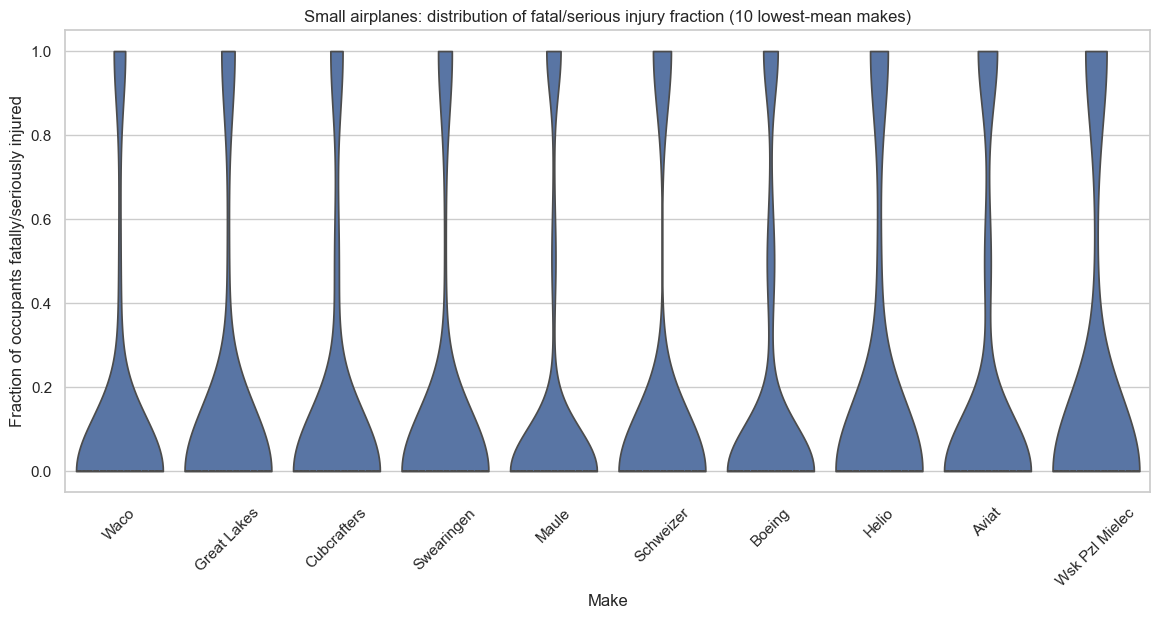

In [9]:
small10 = small_makes.head(10).index
plt.figure(figsize=(14, 6))
sns.violinplot(data=small[small['Make'].isin(small10)], x='Make', y='Fatal.Serious.Frac',
               order=small10, cut=0, inner='quartile', density_norm='width')
plt.title('Small airplanes: distribution of fatal/serious injury fraction (10 lowest-mean makes)')
plt.ylabel('Fraction of occupants fatally/seriously injured')
plt.xticks(rotation=45)
plt.show()

In [10]:
# share of accidents with nobody fatally/seriously injured vs everyone injured
dist = small[small['Make'].isin(small10)].groupby('Make')['Fatal.Serious.Frac'].agg(
    pct_zero=lambda s: (s == 0).mean(), pct_all=lambda s: (s == 1).mean(), median='median')
dist.loc[small10]

,pct_zero,pct_all,median
Make,,,
Waco,0.848,0.111,0.000
Great Lakes,0.852,0.130,0.000
Cubcrafters,0.838,0.118,0.000
Swearingen,0.835,0.129,0.000
Maule,0.816,0.133,0.000
Schweizer,0.829,0.171,0.000
Boeing,0.778,0.131,0.000
Helio,0.779,0.162,0.000
Aviat,0.771,0.170,0.000


**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

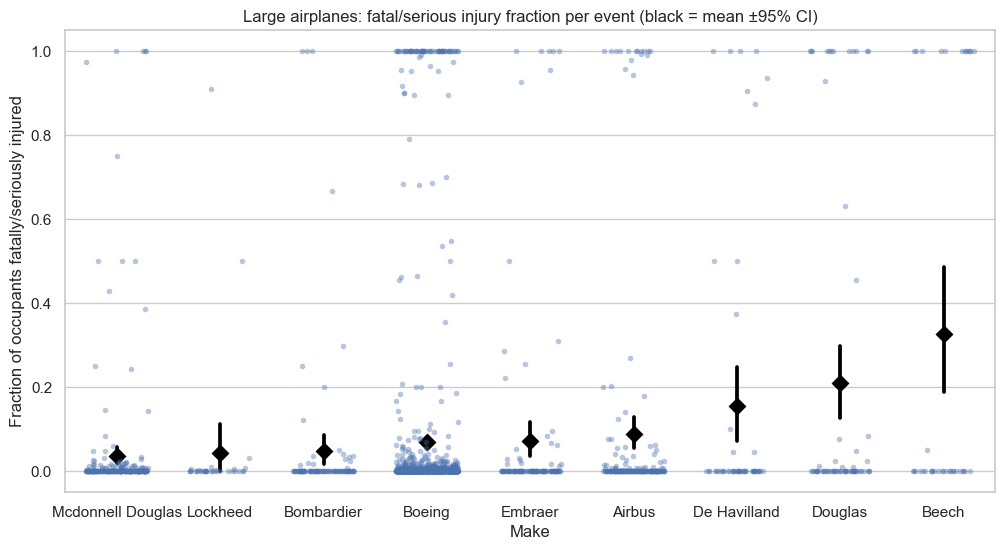

In [11]:
large10 = large_makes.head(10).index
plt.figure(figsize=(12, 6))
sns.stripplot(data=large[large['Make'].isin(large10)], x='Make', y='Fatal.Serious.Frac',
              order=large10, jitter=0.3, alpha=0.4, size=4)
sns.pointplot(data=large[large['Make'].isin(large10)], x='Make', y='Fatal.Serious.Frac',
              order=large10, color='black', linestyle='none', markers='D', errorbar=('ci', 95))
plt.title('Large airplanes: fatal/serious injury fraction per event (black = mean ±95% CI)')
plt.ylabel('Fraction of occupants fatally/seriously injured')
plt.show()

In [12]:
large[large['Make'].isin(large10)].groupby('Make')['Fatal.Serious.Frac'].agg(
    pct_zero=lambda s: (s == 0).mean(), pct_over_half=lambda s: (s > 0.5).mean(), median='median').loc[large10]

,pct_zero,pct_over_half,median
Make,,,
Mcdonnell Douglas,0.756,0.023,0.000
Lockheed,0.735,0.029,0.000
Bombardier,0.816,0.039,0.000
Boeing,0.728,0.064,0.000
Embraer,0.797,0.057,0.000
Airbus,0.730,0.080,0.000
De Havilland,0.755,0.132,0.000
Douglas,0.662,0.206,0.000
Beech,0.649,0.324,0.000


**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

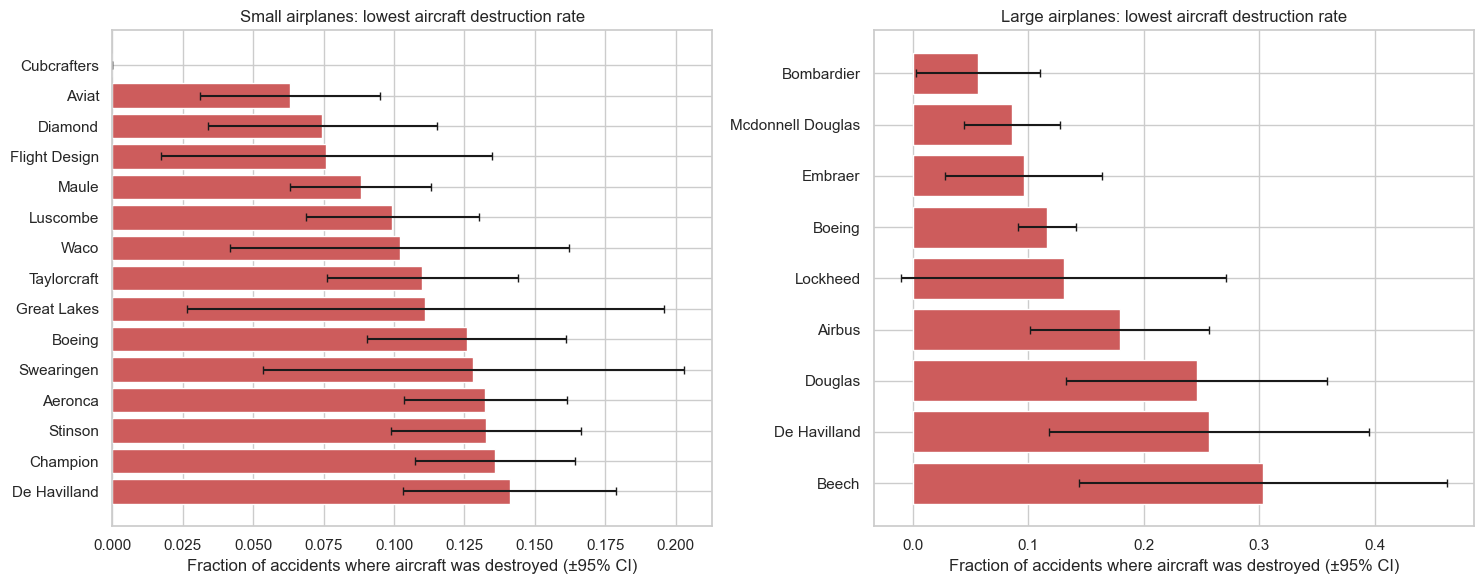

,n_damage_known,destroyed_rate,destroyed_ci95,inj_mean
Make,,,,
Cubcrafters,68,0.000,0.000,0.140
Aviat,222,0.063,0.032,0.200
Diamond,161,0.075,0.041,0.217
Flight Design,79,0.076,0.059,0.354
Maule,488,0.088,0.025,0.159
Luscombe,362,0.099,0.031,0.232
Waco,98,0.102,0.060,0.130
Taylorcraft,327,0.110,0.034,0.299
Great Lakes,54,0.111,0.085,0.139


In [13]:
small_destroyed = small_makes.sort_values('destroyed_rate').head(15)
large_destroyed = large_makes.sort_values('destroyed_rate').head(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, tbl, title in [(axes[0], small_destroyed, 'Small airplanes'), (axes[1], large_destroyed, 'Large airplanes')]:
    ax.barh(tbl.index, tbl['destroyed_rate'], xerr=tbl['destroyed_ci95'], color='indianred', capsize=3)
    ax.invert_yaxis()
    ax.set_title(f'{title}: lowest aircraft destruction rate')
    ax.set_xlabel('Fraction of accidents where aircraft was destroyed (±95% CI)')
plt.tight_layout()
plt.show()
small_destroyed[['n_damage_known', 'destroyed_rate', 'destroyed_ci95', 'inj_mean']]

In [14]:
large_destroyed[['n_damage_known', 'destroyed_rate', 'destroyed_ci95', 'inj_mean']]

,n_damage_known,destroyed_rate,destroyed_ci95,inj_mean
Make,,,,
Bombardier,71,0.056,0.054,0.047
Mcdonnell Douglas,175,0.086,0.042,0.036
Embraer,73,0.096,0.068,0.073
Boeing,628,0.116,0.025,0.069
Lockheed,23,0.130,0.141,0.043
Airbus,95,0.179,0.077,0.089
Douglas,57,0.246,0.113,0.210
De Havilland,39,0.256,0.139,0.156
Beech,33,0.303,0.159,0.326


In [15]:
# Makes that are in the best 15 on BOTH metrics, and how they compare to the group average
for name, tbl, grp in [('Small', small_makes, small), ('Large', large_makes, large)]:
    both = tbl[tbl.index.isin(tbl.sort_values('inj_mean').head(15).index) &
               tbl.index.isin(tbl.sort_values('destroyed_rate').head(15).index)]
    print(f"{name}: group mean injury frac = {grp['Fatal.Serious.Frac'].mean():.3f}, "
          f"group destroyed rate = {grp['Destroyed'].mean():.3f}")
    display(both.sort_values('inj_mean'))

Small: group mean injury frac = 0.273, group destroyed rate = 0.206


,n_events,inj_mean,inj_ci95,n_damage_known,destroyed_rate,destroyed_ci95
Make,,,,,,
Waco,99,0.130,0.064,98,0.102,0.060
Great Lakes,54,0.139,0.091,54,0.111,0.085
Cubcrafters,68,0.140,0.079,68,0.000,0.000
Swearingen,85,0.147,0.074,78,0.128,0.075
Maule,488,0.159,0.031,488,0.088,0.025
Boeing,360,0.172,0.036,342,0.126,0.035
Aviat,223,0.200,0.050,222,0.063,0.032
Stinson,392,0.204,0.037,392,0.133,0.034
Diamond,162,0.217,0.060,161,0.075,0.041


Large: group mean injury frac = 0.077, group destroyed rate = 0.129


,n_events,inj_mean,inj_ci95,n_damage_known,destroyed_rate,destroyed_ci95
Make,,,,,,
Mcdonnell Douglas,266,0.036,0.019,175,0.086,0.042
Lockheed,34,0.043,0.059,23,0.130,0.141
Bombardier,103,0.047,0.035,71,0.056,0.054
Boeing,1210,0.069,0.013,628,0.116,0.025
Embraer,123,0.073,0.041,73,0.096,0.068
Airbus,200,0.089,0.037,95,0.179,0.077
De Havilland,53,0.156,0.090,39,0.256,0.139
Douglas,68,0.210,0.094,57,0.246,0.113
Beech,37,0.326,0.153,33,0.303,0.159


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [16]:
# Is the gap between the best makes and the rest statistically significant? (Mann-Whitney U on injury fraction)
for name, grp, makes in [('Small', small, small_makes.head(5).index), ('Large', large, large_makes.head(3).index)]:
    for m in makes:
        a = grp.loc[grp['Make'] == m, 'Fatal.Serious.Frac']
        b = grp.loc[grp['Make'] != m, 'Fatal.Serious.Frac']
        p = stats.mannwhitneyu(a, b, alternative='less').pvalue
        print(f'{name:5s} {m:20s} mean={a.mean():.3f} vs rest={b.mean():.3f}  n={len(a):5d}  p={p:.2g}')

# Large planes: jet-airliner makes vs older / turboprop makes (De Havilland, Douglas, Beech)
older = ['De Havilland', 'Douglas', 'Beech']
jet = large[large['Make'].isin(large_makes.index) & ~large['Make'].isin(older)]
old = large[large['Make'].isin(older)]
print()
print(f"Large jet-airliner makes: inj={jet['Fatal.Serious.Frac'].mean():.3f}, destroyed={jet['Destroyed'].mean():.3f} (n={len(jet)})")
print(f"Large older/turboprop makes: inj={old['Fatal.Serious.Frac'].mean():.3f}, destroyed={old['Destroyed'].mean():.3f} (n={len(old)})")
print('injury Mann-Whitney p =', f"{stats.mannwhitneyu(jet['Fatal.Serious.Frac'], old['Fatal.Serious.Frac']).pvalue:.2g}")
both = pd.concat([jet.assign(g='jet'), old.assign(g='old')]).dropna(subset=['Destroyed'])
print('destroyed chi-square p =', f"{stats.chi2_contingency(pd.crosstab(both['g'], both['Destroyed']))[1]:.2g}")

Small Waco                 mean=0.130 vs rest=0.274  n=   99  p=0.00039
Small Great Lakes          mean=0.139 vs rest=0.274  n=   54  p=0.0076
Small Cubcrafters          mean=0.140 vs rest=0.274  n=   68  p=0.0046
Small Swearingen           mean=0.147 vs rest=0.274  n=   85  p=0.0026
Small Maule                mean=0.159 vs rest=0.274  n=  488  p=1.4e-09
Large Mcdonnell Douglas    mean=0.036 vs rest=0.083  n=  266  p=0.14
Large Lockheed             mean=0.043 vs rest=0.078  n=   34  p=0.36
Large Bombardier           mean=0.047 vs rest=0.079  n=  103  p=0.055

Large jet-airliner makes: inj=0.065, destroyed=0.112 (n=1936)
Large older/turboprop makes: inj=0.219, destroyed=0.264 (n=158)
injury Mann-Whitney p = 0.0069
destroyed chi-square p = 2.2e-06


#### Discussion: Makes

**Baseline.** Across all accidents, a small airplane occupant has a **27.3%** chance of fatal/serious injury and the aircraft is destroyed in **20.6%** of accidents. For large airplanes the figures are **7.7%** and **12.9%** — large passenger aircraft are much more survivable in an accident.

**Distributions.** The injury fraction is strongly bimodal: for every make, ~75–85% of accidents have *nobody* fatally/seriously injured (median = 0) and a 10–20% tail of accidents injures *everyone* on board. Differences between makes are therefore differences in how often an accident falls into that catastrophic tail, which is why we compare means with confidence intervals and sample sizes rather than medians.

**Small-airplane makes (≥50 events each).**
- **Maule** is the strongest recommendation: low injury fraction (15.9% ± 3.1%) *and* low destruction rate (8.8% ± 2.5%) on a large sample (n = 488). Its advantage over the rest of the small group is highly significant (Mann-Whitney p ≈ 1e-9).
- **Aviat** (destroyed 6.3%, n = 223), **Diamond** (7.5%, n = 162) and **Cubcrafters** (0 of 68 destroyed, injury 14.0%) have the lowest destruction rates; all are also below the group injury average.
- **Waco, Great Lakes, Stinson, Luscombe** are also in the best 15 on both metrics; Waco/Great Lakes are significantly better than average (p < 0.01) but have smaller samples (54–99), so their intervals are wide.
- "Boeing" in the small group is almost entirely the Boeing-Stearman biplane (A75/PT-17), not airliners.
- Makes to treat with caution: **Grumman** has a below-average injury rate but an above-average destruction rate (23.2%).

**Large-airplane makes (≥20 events each).**
- The modern jet-airliner makes — **McDonnell Douglas, Bombardier, Boeing, Embraer, Airbus, Lockheed** — all have injury fractions of 3.6–8.9%. **Bombardier** (destroyed 5.6%) and **McDonnell Douglas** (8.6%) look best on both metrics, with **Boeing** (6.9% injury, 11.6% destroyed, n = 1,210) the best-evidenced.
- However, the differences *between* these makes are **not statistically significant** (e.g. McDonnell Douglas vs the rest p = 0.14, Bombardier p = 0.055). We should not claim one airliner manufacturer is safer than another.
- What *is* significant is the gap between these jet-airliner makes (injury 6.5%, destroyed 11.2%) and older / turboprop large-plane makes **De Havilland, Douglas, Beech** (injury 21.9%, destroyed 26.4%; p = 0.007 and p = 2e-6). Recommendation: favour the modern jet-airliner manufacturers and avoid the older/turboprop types.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [17]:
MIN_EVENTS_TYPE = 10
large_types_tbl = safety_summary(large, 'Make.Model', MIN_EVENTS_TYPE).sort_values('inj_mean')
large_types_tbl

,n_events,inj_mean,inj_ci95,n_damage_known,destroyed_rate,destroyed_ci95
Make.Model,,,,,,
Mcdonnell Douglas MD83,20,0.001,0.001,14,0.071,0.140
Boeing 717200,16,0.001,0.002,8,0.000,0.000
Boeing 7373H4,14,0.002,0.003,9,0.000,0.000
Boeing 747422,12,0.002,0.002,4,0.000,0.000
Boeing 757223,17,0.002,0.002,9,0.000,0.000
Boeing 787,12,0.003,0.005,3,0.000,0.000
Mcdonnell Douglas DC10,10,0.003,0.005,2,0.000,0.000
Mcdonnell Douglas MD88,34,0.003,0.002,26,0.000,0.000
Lockheed L1011,12,0.004,0.005,9,0.000,0.000


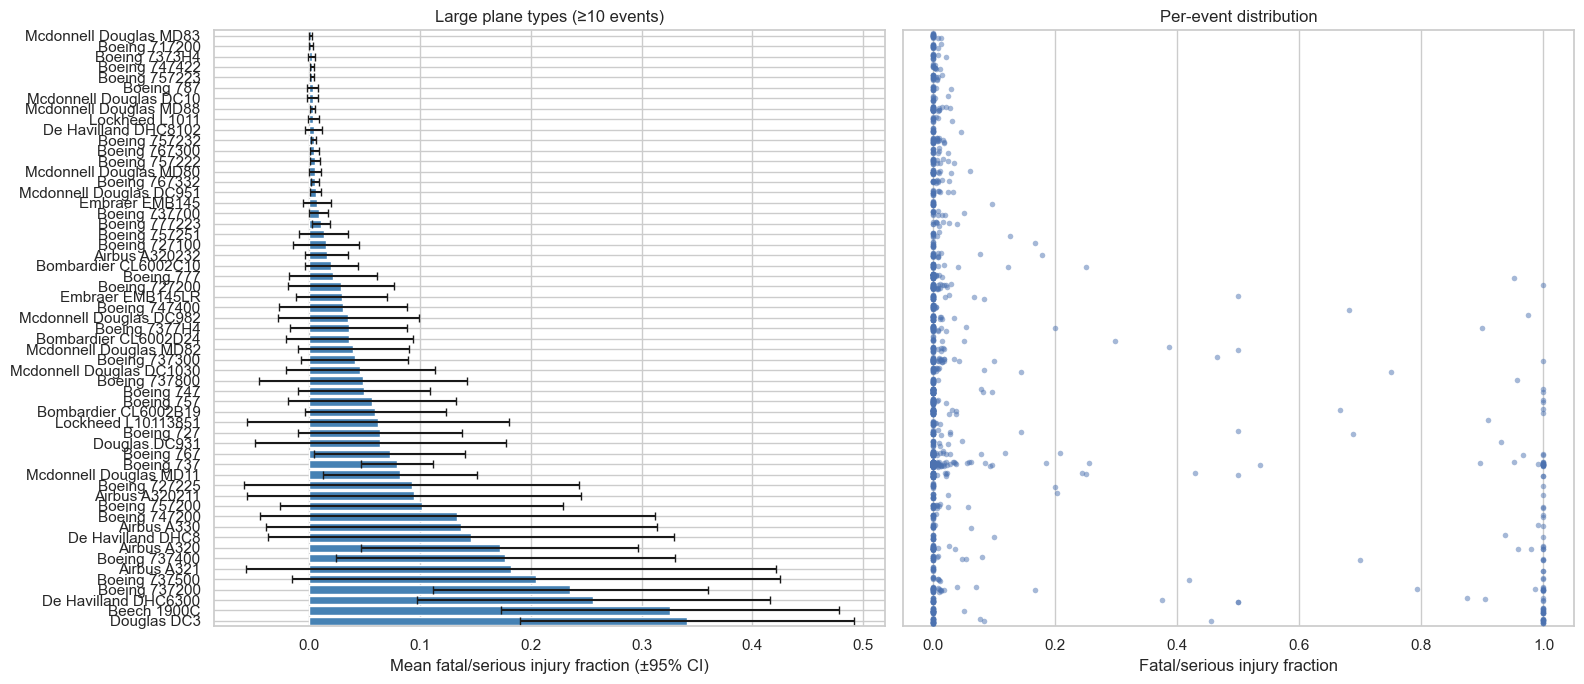

In [18]:
order = large_types_tbl.index
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
axes[0].barh(order, large_types_tbl['inj_mean'], xerr=large_types_tbl['inj_ci95'], color='steelblue', capsize=3)
axes[0].invert_yaxis()
axes[0].set_xlabel('Mean fatal/serious injury fraction (±95% CI)')
axes[0].set_title('Large plane types (≥10 events)')
sns.stripplot(data=large[large['Make.Model'].isin(order)], y='Make.Model', x='Fatal.Serious.Frac',
              order=order, ax=axes[1], alpha=0.5, jitter=0.25, size=4)
axes[1].set_title('Per-event distribution')
axes[1].set_xlabel('Fatal/serious injury fraction')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [19]:
small_types_tbl = safety_summary(small, 'Make.Model', MIN_EVENTS_TYPE).sort_values('inj_mean')
print('Small plane types with at least 10 events:', len(small_types_tbl))
# a type with only ~10 events can reach a mean of 0 by luck; also show the more robust subset with >=50 events
small_types_tbl.head(10)

Small plane types with at least 10 events: 640


,n_events,inj_mean,inj_ci95,n_damage_known,destroyed_rate,destroyed_ci95
Make.Model,,,,,,
Mcdonnell Douglas MD11F,14,0.000,0.000,11,0.091,0.178
Cessna 180C,15,0.000,0.000,15,0.067,0.131
Maule MX7235,22,0.023,0.045,22,0.000,0.000
Maule M4,26,0.038,0.075,26,0.038,0.075
Cessna 560XL,25,0.040,0.078,16,0.125,0.167
Diamond DA42,12,0.042,0.082,12,0.000,0.000
Cessna C172,12,0.042,0.082,12,0.000,0.000
Piper PA18160,33,0.045,0.066,33,0.030,0.059
Cessna L19,11,0.045,0.089,11,0.091,0.178


In [20]:
small_types_50 = safety_summary(small, 'Make.Model', 50).sort_values('inj_mean')
small_types_50.head(10)

,n_events,inj_mean,inj_ci95,n_damage_known,destroyed_rate,destroyed_ci95
Make.Model,,,,,,
Cessna 180A,56,0.071,0.068,56,0.036,0.049
Beech 1900D,56,0.073,0.067,48,0.083,0.079
Piper PA20,132,0.080,0.046,132,0.053,0.038
Cessna A185E,64,0.086,0.059,63,0.032,0.044
Cessna 185F,101,0.087,0.051,100,0.090,0.056
Cessna 305A,84,0.109,0.063,83,0.108,0.067
Stinson 1081,85,0.110,0.061,85,0.141,0.074
Cessna 180,595,0.111,0.024,593,0.078,0.022
Cessna 180H,96,0.114,0.060,96,0.073,0.052


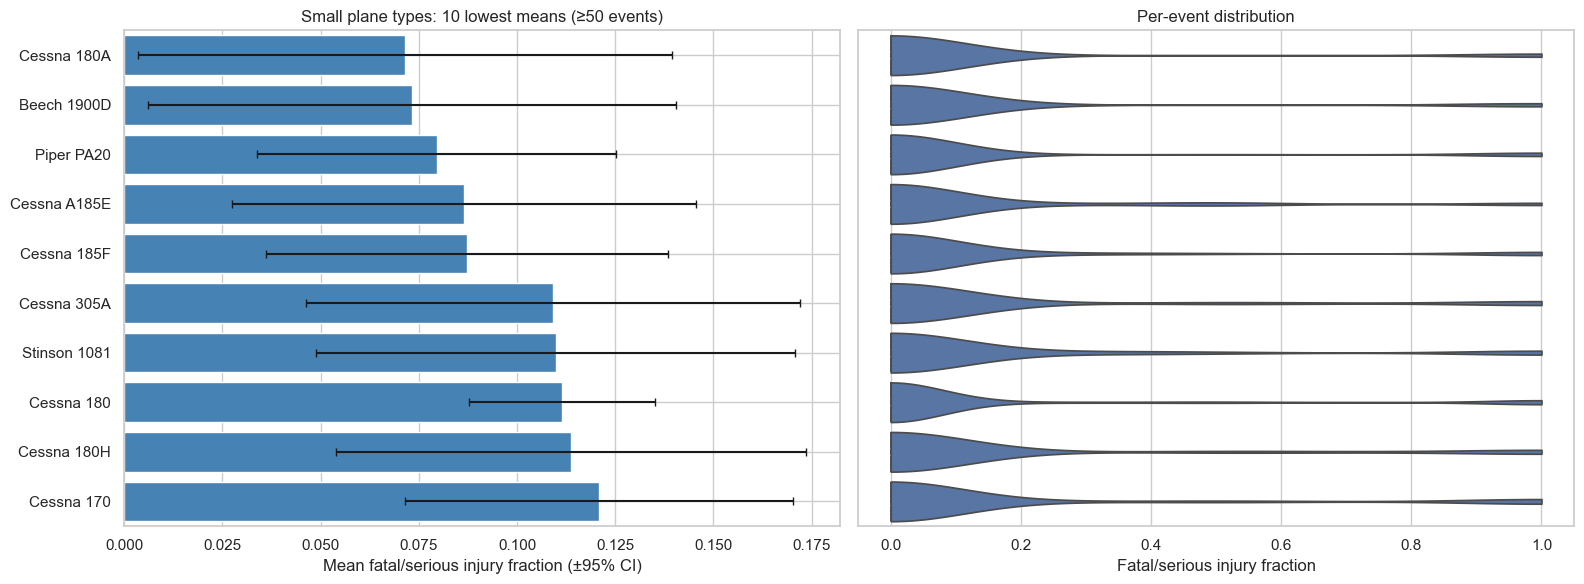

In [21]:
order = small_types_50.head(10).index
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
axes[0].barh(order, small_types_50.loc[order, 'inj_mean'], xerr=small_types_50.loc[order, 'inj_ci95'],
             color='steelblue', capsize=3)
axes[0].invert_yaxis()
axes[0].set_xlabel('Mean fatal/serious injury fraction (±95% CI)')
axes[0].set_title('Small plane types: 10 lowest means (≥50 events)')
sns.violinplot(data=small[small['Make.Model'].isin(order)], y='Make.Model', x='Fatal.Serious.Frac',
               order=order, ax=axes[1], cut=0, inner='quartile', density_norm='width')
axes[1].set_title('Per-event distribution')
axes[1].set_xlabel('Fatal/serious injury fraction')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [22]:
# destruction rate for the recommended types, for comparison with group averages
print('Small group destroyed rate:', round(small['Destroyed'].mean(), 3))
print('Large group destroyed rate:', round(large['Destroyed'].mean(), 3))
pd.concat([small_types_50.head(10).assign(Size='Small'), large_types_tbl.head(8).assign(Size='Large')])[
    ['Size', 'n_events', 'inj_mean', 'inj_ci95', 'destroyed_rate', 'destroyed_ci95']]

Small group destroyed rate: 0.206
Large group destroyed rate: 0.129


,Size,n_events,inj_mean,inj_ci95,destroyed_rate,destroyed_ci95
Make.Model,,,,,,
Cessna 180A,Small,56,0.071,0.068,0.036,0.049
Beech 1900D,Small,56,0.073,0.067,0.083,0.079
Piper PA20,Small,132,0.080,0.046,0.053,0.038
Cessna A185E,Small,64,0.086,0.059,0.032,0.044
Cessna 185F,Small,101,0.087,0.051,0.090,0.056
Cessna 305A,Small,84,0.109,0.063,0.108,0.067
Stinson 1081,Small,85,0.110,0.061,0.141,0.074
Cessna 180,Small,595,0.111,0.024,0.078,0.022
Cessna 180H,Small,96,0.114,0.060,0.073,0.052


#### Discussion: Specific plane types

**Large planes (≥10 events per type).** The safest types have essentially zero risk of serious injury when an accident happens: **MD-88, MD-80/MD-83, Boeing 717-200, 757 variants, 767-300, 787, A320-232, Embraer EMB-145** all have mean fatal/serious fractions below ~2%, and most were never destroyed. The stripplot shows that almost all accidents for these types sit at 0, with only rare outliers (typically a single turbulence injury among hundreds of passengers). Caveats: samples are small (10–47 per type), damage is unknown for many large-plane records, and the confidence intervals of the top ~25 types overlap — so these should be read as a *shortlist* of proven types rather than a strict ranking. Types with the most evidence behind a low rate are the **MD-88** (n = 34), **Boeing 757-232** (n = 26) and **Boeing 777** family (n = 47).

**Small planes.** With only 10 events, several types reach a mean of 0 by chance (and a few freighters slip into the small group), so we base recommendations on types with **≥50 events**:
- The **Cessna 180/185 family** dominates: Cessna 180 (n = 595, injury 11.1% ± 2.4%, destroyed 7.8%), 180A, 180H, 185F and A185E — all at roughly 7–11% injury and 3–9% destruction, versus 27.3% / 20.6% for small planes overall. This is the most robust small-plane recommendation in the data.
- **Piper PA-20** (n = 132, 8.0% injury, 5.3% destroyed) and **Cessna 170** (n = 151) are also strong.
- **Beech 1900D** (19-seat commuter, n = 56) has a low injury rate (7.3%) and is a candidate for an operator needing a larger "small" aircraft.
- The violin plots show these types have the same "mostly zero" shape as everything else, but with a much thinner tail at 1.0 (all occupants injured).

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

#### Factor 1: Weather condition (VMC vs IMC)
VMC = visual meteorological conditions, IMC = instrument meteorological conditions (cloud, low visibility). `Unknown` weather is excluded from the comparison.

In [23]:
wx = df[df['Weather.Condition'].isin(['VMC', 'IMC'])]
wx_tbl = safety_summary(wx, ['Size', 'Weather.Condition'])
wx_tbl

n_events  inj_mean  inj_ci95  n_damage_known  \
Size  Weather.Condition                                                 
Large IMC                     233     0.168     0.045             145   
      VMC                    1102     0.043     0.011             651   
Small IMC                    4194     0.689     0.014            4164   
      VMC                   48558     0.223     0.004           48203   

                         destroyed_rate  destroyed_ci95  
Size  Weather.Condition                                  
Large IMC                         0.262           0.072  
      VMC                         0.063           0.019  
Small IMC                         0.598           0.015  
      VMC                         0.163           0.003

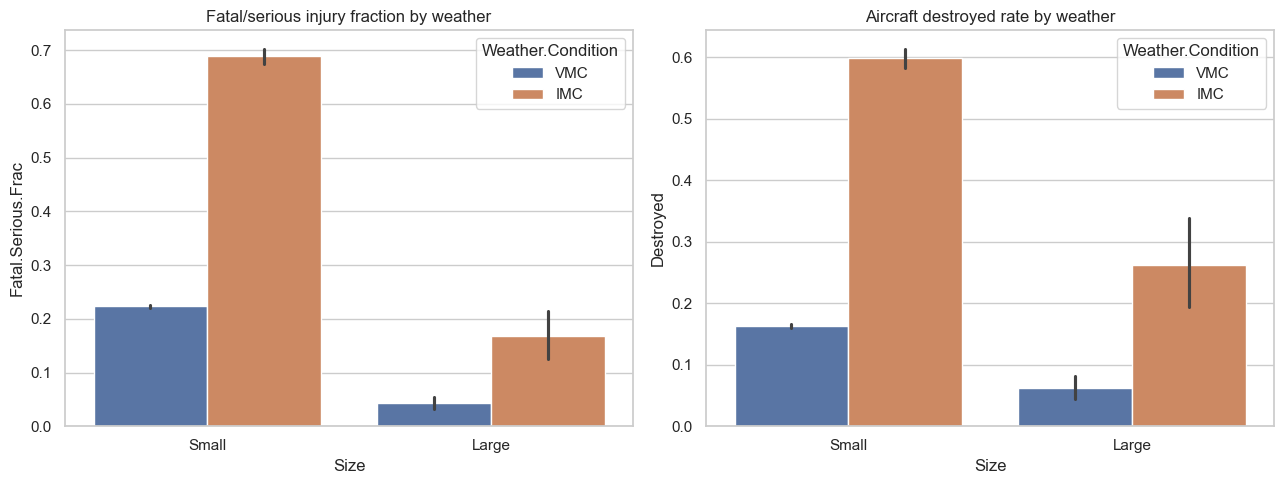

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=wx, x='Size', y='Fatal.Serious.Frac', hue='Weather.Condition', ax=axes[0], errorbar=('ci', 95))
axes[0].set_title('Fatal/serious injury fraction by weather')
sns.barplot(data=wx, x='Size', y='Destroyed', hue='Weather.Condition', ax=axes[1], errorbar=('ci', 95))
axes[1].set_title('Aircraft destroyed rate by weather')
plt.tight_layout()
plt.show()

In [25]:
# significance: chi-square on destroyed vs weather, Mann-Whitney on injury fraction
for size in ['Small', 'Large']:
    sub = wx[wx['Size'] == size]
    ct = pd.crosstab(sub['Weather.Condition'], sub['Destroyed'])
    chi_p = stats.chi2_contingency(ct)[1]
    mw_p = stats.mannwhitneyu(sub.loc[sub['Weather.Condition'] == 'IMC', 'Fatal.Serious.Frac'],
                              sub.loc[sub['Weather.Condition'] == 'VMC', 'Fatal.Serious.Frac']).pvalue
    print(f'{size}: destroyed chi-square p={chi_p:.2g}; injury Mann-Whitney p={mw_p:.2g}')

Small: destroyed chi-square p=0; injury Mann-Whitney p=0
Large: destroyed chi-square p=1.3e-12; injury Mann-Whitney p=4.2e-12


**Weather — interpretation.** Instrument meteorological conditions (IMC) are the single largest risk factor in the data:
- *Small planes:* fatal/serious injury fraction is **68.9%** in IMC vs **22.3%** in VMC, and the aircraft is destroyed in **59.8%** vs **16.3%** of accidents (n = 4,194 vs 48,558; both p ≈ 0).
- *Large planes:* **16.8%** vs **4.3%** injury and **26.2%** vs **6.3%** destroyed (p ≈ 1e-12).

Accidents in poor visibility (controlled flight into terrain, loss of control in cloud) are far more violent. Insurers should weight exposure to IMC operations — and pilot instrument rating/currency — heavily, especially for small aircraft.

#### Factor 2: Phase of flight
`Unknown` phase is excluded, and only phases with at least 30 events in the group are shown.

In [26]:
ph = df[~df['Broad.phase.of.flight'].isin(['Unknown', 'Other'])]
phase_small = safety_summary(ph[ph['Size'] == 'Small'], 'Broad.phase.of.flight', 30).sort_values('inj_mean')
phase_large = safety_summary(ph[ph['Size'] == 'Large'], 'Broad.phase.of.flight', 30).sort_values('inj_mean')
phase_small

,n_events,inj_mean,inj_ci95,n_damage_known,destroyed_rate,destroyed_ci95
Broad.phase.of.flight,,,,,,
Taxi,1223,0.021,0.007,1203,0.021,0.008
Landing,10904,0.035,0.003,10894,0.042,0.004
Standing,476,0.165,0.027,394,0.132,0.033
Takeoff,8014,0.226,0.009,7991,0.215,0.009
Go-around,1091,0.297,0.026,1088,0.285,0.027
Descent,1144,0.346,0.027,1136,0.333,0.027
Approach,4087,0.350,0.014,4063,0.297,0.014
Cruise,6530,0.350,0.011,6479,0.341,0.012
Climb,1239,0.432,0.027,1224,0.437,0.028


In [27]:
phase_large

,n_events,inj_mean,inj_ci95,n_damage_known,destroyed_rate,destroyed_ci95
Broad.phase.of.flight,,,,,,
Taxi,141,0.003,0.003,108,0.000,0.000
Standing,64,0.015,0.009,36,0.000,0.000
Descent,80,0.022,0.025,18,0.000,0.000
Landing,115,0.033,0.030,93,0.075,0.054
Takeoff,123,0.042,0.035,87,0.080,0.057
Climb,71,0.043,0.043,35,0.086,0.094
Cruise,141,0.060,0.036,50,0.160,0.103
Approach,86,0.109,0.064,54,0.148,0.096


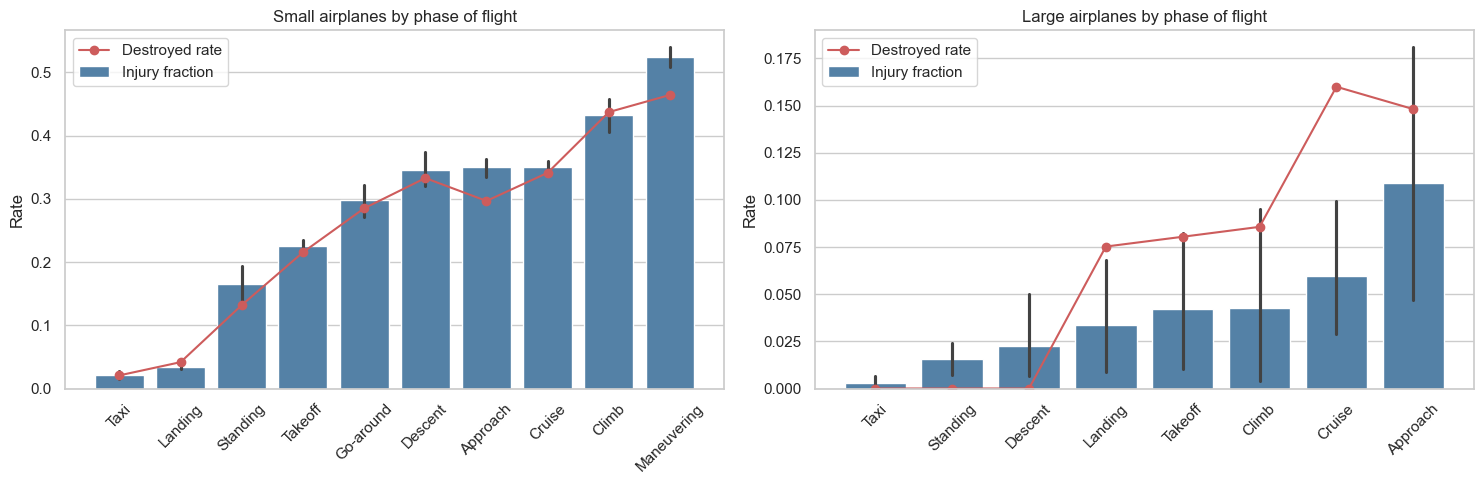

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = phase_small.index
sns.barplot(data=ph[ph['Size'] == 'Small'], x='Broad.phase.of.flight', y='Fatal.Serious.Frac',
            order=order, ax=axes[0], color='steelblue', errorbar=('ci', 95), label='Injury fraction')
axes[0].plot(range(len(order)), phase_small.loc[order, 'destroyed_rate'], 'o-', color='indianred', label='Destroyed rate')
axes[0].set_title('Small airplanes by phase of flight')
axes[0].legend(); axes[0].tick_params(axis='x', rotation=45); axes[0].set_ylabel('Rate'); axes[0].set_xlabel('')
order = phase_large.index
sns.barplot(data=ph[ph['Size'] == 'Large'], x='Broad.phase.of.flight', y='Fatal.Serious.Frac',
            order=order, ax=axes[1], color='steelblue', errorbar=('ci', 95), label='Injury fraction')
axes[1].plot(range(len(order)), phase_large.loc[order, 'destroyed_rate'], 'o-', color='indianred', label='Destroyed rate')
axes[1].set_title('Large airplanes by phase of flight')
axes[1].legend(); axes[1].tick_params(axis='x', rotation=45); axes[1].set_ylabel('Rate'); axes[1].set_xlabel('')
plt.tight_layout()
plt.show()

In [29]:
sub = ph[(ph['Size'] == 'Small') & ph['Broad.phase.of.flight'].isin(phase_small.index)]
print('Small: Kruskal-Wallis on injury fraction across phases p =',
      f"{stats.kruskal(*[g['Fatal.Serious.Frac'] for _, g in sub.groupby('Broad.phase.of.flight')]).pvalue:.2g}")
print('Small: chi-square on destroyed across phases p =',
      f"{stats.chi2_contingency(pd.crosstab(sub['Broad.phase.of.flight'], sub['Destroyed']))[1]:.2g}")

Small: Kruskal-Wallis on injury fraction across phases p = 0
Small: chi-square on destroyed across phases p = 0


**Phase of flight — interpretation.** For small planes the phase is strongly associated with outcome (Kruskal-Wallis and chi-square p ≈ 0):
- **Taxi (2.1%)** and **Landing (3.5%)** accidents are frequent but rarely injure anyone or destroy the aircraft — they are low-speed, near-ground events (runway excursions, hard landings).
- **Maneuvering (52.4% injury, 46.4% destroyed)**, **Climb (43.2%, 43.7%)**, **Cruise** and **Approach** (~35%) are the dangerous phases: higher speed/altitude and loss-of-control events.
- Large planes show the same ordering (taxi/standing ≈ 0%, approach/cruise highest at 6–11%), but with much smaller samples and overlapping intervals.

So the *number* of accidents is dominated by landing/takeoff, but the *severity* is driven by maneuvering and airborne loss of control — relevant for pricing low-altitude maneuvering operations (aerial application, banner towing, aerobatics).

#### Factor 3: Number of engines (small airplanes)

In [30]:
eng = small[small['Number.of.Engines'].isin([1, 2])]
eng_tbl = safety_summary(eng, 'Number.of.Engines')
eng_tbl

,n_events,inj_mean,inj_ci95,n_damage_known,destroyed_rate,destroyed_ci95
Number.of.Engines,,,,,,
1.000,46495,0.251,0.004,46242,0.184,0.004
2.000,6291,0.351,0.011,6144,0.312,0.012


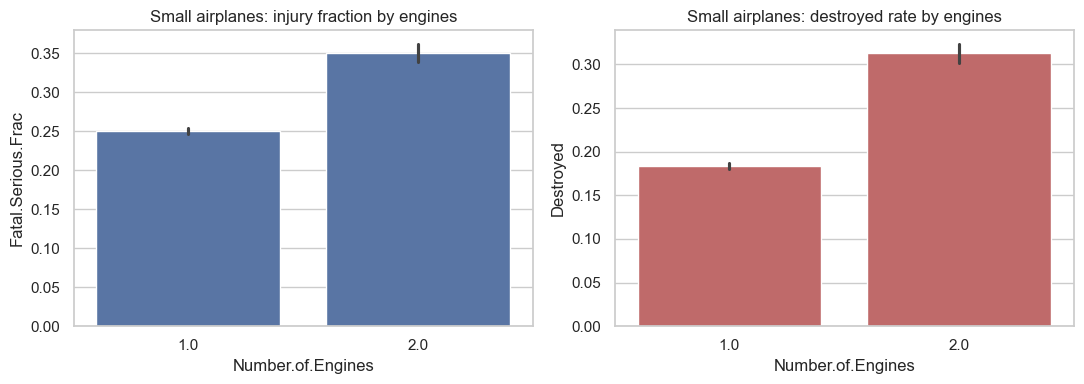

chi-square destroyed p = 5.8e-125


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=eng, x='Number.of.Engines', y='Fatal.Serious.Frac', ax=axes[0], errorbar=('ci', 95))
axes[0].set_title('Small airplanes: injury fraction by engines')
sns.barplot(data=eng, x='Number.of.Engines', y='Destroyed', ax=axes[1], errorbar=('ci', 95), color='indianred')
axes[1].set_title('Small airplanes: destroyed rate by engines')
plt.tight_layout()
plt.show()
print('chi-square destroyed p =', f"{stats.chi2_contingency(pd.crosstab(eng['Number.of.Engines'], eng['Destroyed']))[1]:.2g}")

**Number of engines (small planes) — interpretation.** Surprisingly, twin-engine small aircraft fare *worse* than singles when an accident happens (injury 35.1% vs 25.1%, destroyed 31.2% vs 18.4%, p ≈ 1e-125). This is most likely confounding rather than a causal effect of the second engine: twins fly faster, more often in IMC and on business/charter missions, and engine-out loss of control in a twin is notoriously severe. The point for the client is that a second engine should **not** be assumed to reduce loss severity.

## Summary of Recommendations

**Small aircraft (≤20 occupants)**
- Makes: **Maule**, **Aviat**, **Diamond**, **Cubcrafters**, plus Waco/Stinson/Luscombe — all below the small-plane average on both injury and destruction.
- Types: **Cessna 180 / 185 family**, **Piper PA-20**, **Cessna 170**; **Beech 1900D** for a 19-seat commuter.

**Large aircraft (>20 occupants)**
- Makes: modern jet-airliner manufacturers — **Boeing, McDonnell Douglas, Bombardier, Embraer, Airbus** (no statistically significant difference between them); avoid older/turboprop large types (De Havilland, Douglas, Beech large models), which are ~3× worse.
- Types: **MD-80/88 series, Boeing 717 / 757 / 767 / 777 / 787, Airbus A320, Embraer EMB-145**.

**Factors affecting safety**
1. **Weather:** IMC accidents are ~3× more likely to cause fatal/serious injury and ~3–4× more likely to destroy the aircraft.
2. **Phase of flight:** taxi/landing accidents are benign; maneuvering, climb and cruise accidents are the most severe.
3. **Engines:** twin-engine small aircraft do not have less severe accidents than singles.

*Limitations:* the data contain only accidents (no flight-hours), so these are **severity-given-an-accident** measures, not accident *rates*; plane size is inferred from recorded occupants; and many large-plane records lack damage information.